In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler


DATASET REFERENCE
https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics?resource=download

author: zeyad mohamed

In [2]:
df = pd.read_csv('netflix_customer_churn.csv')

df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


I will be using KNN because I feel that the features in this dataset are a good mix of categorical values. I also don't have to worry about independence for these features as I would with Naive Bayes. I want to predict whether someone will churn or not, and KNN is good with binary classifications. I plan on playing around with the amount of neighbors to find a good accuracy score. 

In [3]:
# drop customer_id because it won't help the model, and churned because that is our target
X = df.drop(columns=["customer_id", "churned"])
y = df["churned"]

In [4]:
# encoding categorical columns and doing a 80 / 20 split for the knn model
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42, stratify=y)

In [5]:
# scaling the training and test set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

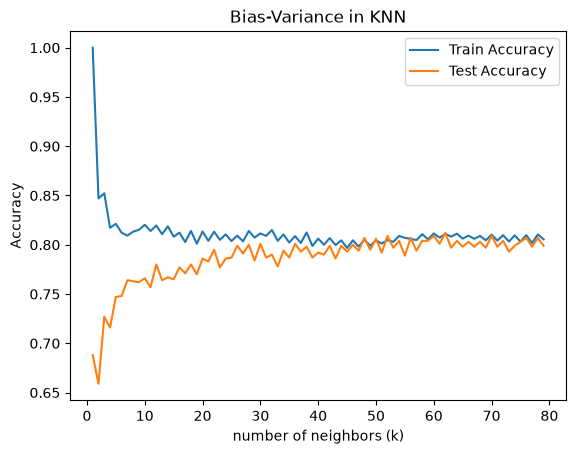

In [6]:
# declare KNN model in k-sweep and plot results. 

k_values = range(1,80)
train_scores = []
test_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_scores.append(model.score(X_train_scaled, y_train))
    test_scores.append(model.score(X_test_scaled, y_test))

plt.plot(k_values, train_scores, label="Train Accuracy")
plt.plot(k_values, test_scores, label="Test Accuracy")
plt.xlabel("number of neighbors (k)")
plt.ylabel("Accuracy")
plt.title("Bias-Variance in KNN")
plt.legend()
plt.show()

Both the train and test scores start to merge right around 50 neighbors and they plateau for the most part after that. I found that 50 neighbors as seen below gives the a very good score for accuracy and auc and it doesn't change much as you increase k. Also, to optimize costs I will choose the smallest k after the lines start to converge which is around 50. 

In [7]:
finalmod = KNeighborsClassifier(n_neighbors=50)
finalmod.fit(X_train_scaled, y_train)
y_pred = finalmod.predict(X_test_scaled)

In [8]:
# y_prob is predicted probability of churn for the test customers. roc_auc_score at .89 shows the model separates the classes well
y_prob = finalmod.predict_proba(X_test_scaled)[:,1]
print(roc_auc_score(y_test, y_prob))

0.8994203791336488


In [9]:
# all the scores, I played around with n_neighbors and found that 50 produced solid numbers
print(classification_report(y_test, y_pred, target_names=["Not Churned", "Churned"]))

              precision    recall  f1-score   support

 Not Churned       0.86      0.73      0.79       497
     Churned       0.77      0.88      0.82       503

    accuracy                           0.81      1000
   macro avg       0.81      0.81      0.80      1000
weighted avg       0.81      0.81      0.80      1000



In [10]:
cross_val_score(KNeighborsClassifier(n_neighbors=50), X_train_scaled, y_train, cv=5).mean()

np.float64(0.7815000000000001)

Text(50.38563368055554, 0.5, 'Actual')

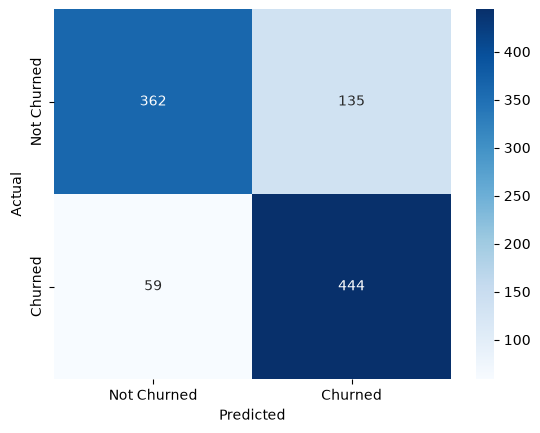

In [11]:
# plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not Churned", "Churned"], yticklabels=["Not Churned", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")

In conclusion, I felt that the KNN model was a good choice in model to use for my goal of predicting customer churn at netflix. It was a simple binary classification, and from the auc score of .89, and the accuracy score of .81(k=50). The model was able to separate churn(or not) well across more than the 0.5 cutoff. The bias-variance plot showed that 50 neighbors was found to produce one of the highest accuracy scores, any k larger than that didn't add much value. I chose k=50 to optimize costs and because it doesn't have much over-fitting. This model also favors False positives, which is preferred for this situation.